<a href="https://colab.research.google.com/github/hazalbese7/telecom-customer-churn-prediction/blob/main/01_Exploratory_Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Telecom Customer Churn Analysis & Prediction

**Author:** Hazal Beşe  
**Tools:** Python, Pandas, NumPy, Matplotlib  
**Dataset:** IBM Telco Customer Churn

## Project Objective

This project investigates customer churn patterns in a telecommunications dataset. The initial phase focuses on data quality, exploratory data analysis, and identifying relationships between churn and customer characteristics.

The next phase will involve preparing the dataset and developing a machine learning model to predict customer churn.

**Research Questions**

- How does contract type relate to customer churn?
- Do customers who churn have different average monthly charges?
- How does observed customer tenure relate to churn?

**Note:** This project uses a public educational dataset, not actual Vodafone customer data.

## 1. Import Libraries & Load Data

We import the required libraries and load the dataset.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Data Inspection & Cleaning

We inspect the dataset, identify missing values,
and prepare the data for further analysis.

In [5]:
df.shape
df.info()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [6]:
df["TotalCharges"].str.strip().eq("").sum()

np.int64(11)

In [7]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

df["TotalCharges"].isnull().sum()

np.int64(11)

In [8]:
mask = (df["tenure"] == 0) & (df["TotalCharges"].isnull())

print("Rows to fill:", mask.sum())

df.loc[mask, "TotalCharges"] = 0

print("Remaining missing values:",
      df["TotalCharges"].isnull().sum())

Rows to fill: 11
Remaining missing values: 0


Eleven missing TotalCharges values were identified among customers with zero tenure. These values were imputed as zero under the assumption that accumulated charges had not yet been recorded. This assumption should be considered when interpreting the results.

### 3.1 Contract Type vs. Churn

This analysis examines the relationship between contract type and customer churn.

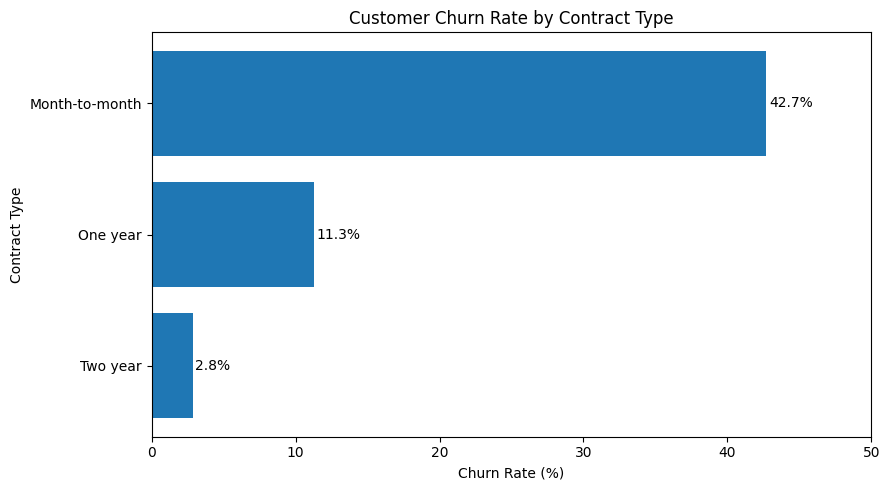

In [9]:
# Convert Churn values into binary format
df["Churn_Binary"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Calculate churn rate for each contract type
churn_rates = df.groupby("Contract")["Churn_Binary"].mean() * 100

# Sort churn rates from highest to lowest
sorted_churn_rates = churn_rates.sort_values(ascending=False)

# Create horizontal bar chart
plt.figure(figsize=(9, 5))

bars = plt.barh(
    sorted_churn_rates.index,
    sorted_churn_rates.values
)

plt.gca().invert_yaxis()

plt.bar_label(bars, fmt="%.1f%%", padding=2)

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Churn Rate (%)")
plt.ylabel("Contract Type")
plt.xlim(0, 50)

plt.tight_layout()
plt.show()

### 3.2 Monthly Charges vs. Churn

This analysis compares the average monthly charges of customers who churned and those who stayed.

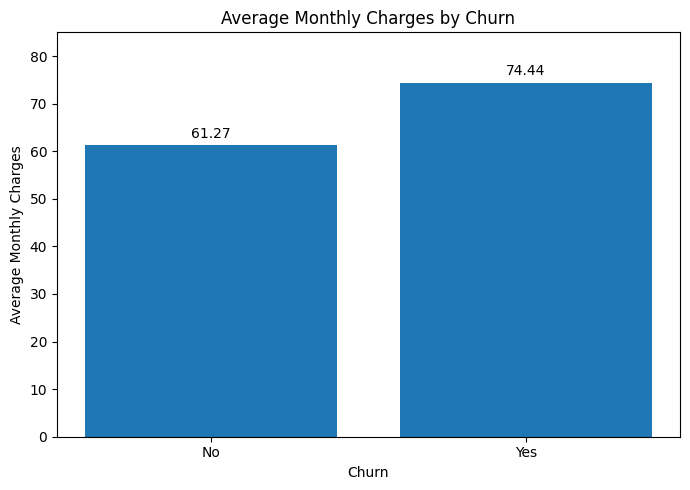

In [10]:
# Calculate average monthly charges by churn status
avg_monthly_charges = df.groupby("Churn")["MonthlyCharges"].mean()

# Create vertical bar chart
plt.figure(figsize=(7, 5))

bars = plt.bar(
    avg_monthly_charges.index,
    avg_monthly_charges.values
)

plt.bar_label(bars, fmt="%.2f", padding=3)

plt.title("Average Monthly Charges by Churn")
plt.xlabel("Churn")
plt.ylabel("Average Monthly Charges")
plt.ylim(0, 85)

plt.tight_layout()
plt.show()

### 3.3 Tenure Groups vs. Churn

This analysis examines how observed customer churn rates differ across tenure groups.

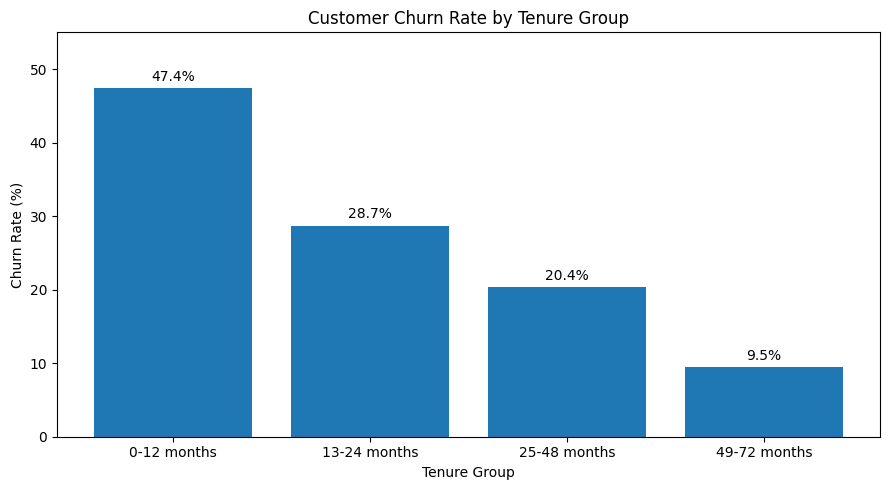

In [11]:
# Define tenure group boundaries
bins = [-1, 12, 24, 48, 72]

# Define group labels
labels = [
    "0-12 months",
    "13-24 months",
    "25-48 months",
    "49-72 months"
]

# Create tenure groups
df["Tenure_Group"] = pd.cut(
    df["tenure"],
    bins=bins,
    labels=labels
)

# Calculate churn rates by tenure group
tenure_churn_rates = (
    df.groupby("Tenure_Group", observed=True)["Churn_Binary"]
    .mean() * 100
)

# Create vertical bar chart
plt.figure(figsize=(9, 5))

bars = plt.bar(
    tenure_churn_rates.index.astype(str),
    tenure_churn_rates.values
)

plt.bar_label(bars, fmt="%.1f%%", padding=3)

plt.title("Customer Churn Rate by Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 55)

plt.tight_layout()
plt.show()

## Exploratory Data Analysis — Key Findings

**1. Contract Type and Customer Churn**

Customers with month-to-month contracts showed the highest churn rate (42.7%), while customers with two-year contracts had the lowest churn rate (2.8%). This indicates a strong descriptive association between contract type and customer churn.

**2. Monthly Charges and Customer Churn**

Customers who churned had higher average monthly charges (approximately 74.44) compared to customers who stayed (approximately 61.27). This suggests that monthly charges may be relevant when examining customer churn.

**3. Customer Tenure and Churn**

Churn rates decreased across longer tenure groups:

- 0–12 months: 47.43%
- 13–24 months: 28.71%
- 25–48 months: 20.38%
- 49–72 months: 9.51%

Customers with shorter observed tenure showed substantially higher churn rates.

**4. Data Quality**

The dataset contains 7,043 customer records. Eleven missing `TotalCharges` values were identified after converting the column to a numeric type. These records all had zero tenure. Missing values were imputed as zero under the assumption that no accumulated charges had yet been recorded.

**Conclusion**

Contract type, monthly charges, and customer tenure show meaningful descriptive relationships with churn. These findings motivate further analysis and predictive modeling, but do not establish causation.